In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [7]:
import pandas as pd

df = pd.read_csv(
    '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv',
    encoding='latin-1'
)

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



# Naive Bayes Classification — SMS Spam Detection

## 1. Introduction

Naive Bayes is a supervised machine learning algorithm based on Bayes' Theorem. It is widely used for classification, particularly text classification.

In this project, we will classify SMS messages into two categories:

- **Spam:** Unwanted or suspicious messages.
- **Ham:** Normal and legitimate messages.

### Objective
Build a machine learning model that predicts whether an SMS message is spam or ham based on its text.

### Algorithm
Multinomial Naive Bayes (`MultinomialNB`).

### Dataset
SMS Spam Collection dataset from Kaggle.

### Applications
- Email spam filtering
- SMS spam detection
- Text classification
- Document categorization



## 2. Mathematical Foundation — Bayes' Theorem

Naive Bayes is based on Bayes' Theorem:

P(C|X) = [P(X|C) * P(C)] / P(X)

Where:

- P(C|X): Posterior probability — probability of the class given the evidence.
- P(X|C): Likelihood — probability of the evidence given the class.
- P(C): Prior probability — probability of the class before observing the evidence.
- P(X): Evidence — overall probability of observing the evidence.

### Why is it called Naive Bayes?

It assumes that features are conditionally independent given the target class.

### Why Multinomial Naive Bayes?

Multinomial Naive Bayes is suitable for text classification when messages are represented using word counts or other non-negative features, such as TF-IDF.


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from sklearn.metrics import(
   accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,ConfusionMatrixDisplay
)


## 3. Loading the Dataset

We use the SMS Spam Collection dataset downloaded from Kaggle.

Important columns in the original dataset:

- `v1`: Target label — spam or ham.
- `v2`: SMS message text.

The CSV file is loaded using Pandas.

We specify `encoding='latin-1'` because the dataset may contain characters that cannot be decoded using UTF-8.


In [9]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

display(df.head(10))

Shape: (5572, 5)

Columns:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Missing values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicate records: 403


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [10]:
df = df[['v1', 'v2']].copy()

df.columns = ['label', 'message']

df = df.dropna()
df = df.drop_duplicates()

print("Cleaned dataset shape:", df.shape)

display(df.head())

print("\nTarget counts:")
print(df['label'].value_counts())

Cleaned dataset shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Target counts:
label
ham     4516
spam     653
Name: count, dtype: int64



## 6. Target Distribution

The target variable contains two classes: ham and spam.

We use a bar chart to visualize the number of messages belonging to each class.

This helps us determine whether the dataset is balanced or imbalanced.

When one class occurs much more frequently than another, accuracy alone may not adequately describe model performance.


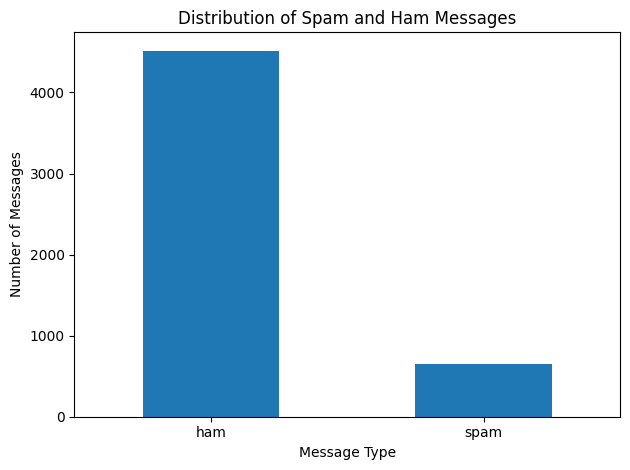

In [11]:
df['label'].value_counts().plot(
    kind='bar',
    xlabel='Message Type',
    ylabel='Number of Messages',
    title='Distribution of Spam and Ham Messages'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
X = df['message']
y = df['label']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (5169,)
Target shape: (5169,)


0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [14]:
example_messages = [
    "win a prize",
    "win a free prize"
]

vectorizer_demo = CountVectorizer()

example_matrix = vectorizer_demo.fit_transform(example_messages)

print("Vocabulary:")
print(vectorizer_demo.get_feature_names_out())

print("\nWord count matrix:")
print(example_matrix.toarray())

Vocabulary:
['free' 'prize' 'win']

Word count matrix:
[[0 1 1]
 [1 1 1]]


In [15]:
model = Pipeline([
    ('vectorizer', CountVectorizer()),
    ('naive_bayes', MultinomialNB())
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [16]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred
})

display(results.head(10))

,Actual,Predicted
0,ham,ham
1,ham,ham
2,ham,ham
3,ham,ham
4,ham,ham
5,ham,ham
6,ham,ham
7,ham,ham
8,ham,ham
9,ham,ham



## 12. Model Evaluation

We evaluate the model using four important metrics.

### Accuracy
The proportion of all predictions that are correct.

Accuracy = Correct Predictions / Total Predictions

### Precision
Of all messages predicted as spam, how many are actually spam?

Precision = TP / (TP + FP)

### Recall
Of all actual spam messages, how many were correctly identified?

Recall = TP / (TP + FN)

### F1-score
The harmonic mean of precision and recall.

F1-score = 2 * Precision * Recall / (Precision + Recall)

These metrics provide a more complete picture of model performance than accuracy alone.


In [17]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (spam): {precision_score(y_test, y_pred, pos_label='spam'):.4f}")
print(f"Recall (spam): {recall_score(y_test, y_pred, pos_label='spam'):.4f}")
print(f"F1-score (spam): {f1_score(y_test, y_pred, pos_label='spam'):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9865
Precision (spam): 0.9756
Recall (spam): 0.9160
F1-score (spam): 0.9449

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.92      0.94       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



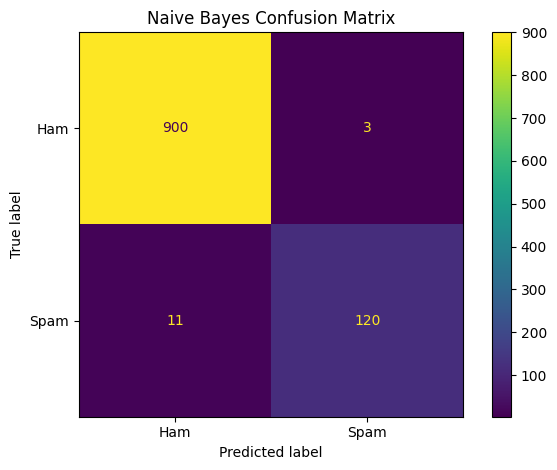

In [18]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['ham', 'spam']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot()
plt.title('Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.show()


## 14. Predicting New Messages

We can use the trained model to classify messages that were not part of the dataset.

The Pipeline automatically performs text vectorization and classification.

- `predict()` returns the predicted label.
- `predict_proba()` returns estimated probabilities for each class.

These probabilities represent the model's estimates and are not guarantees of a message's legitimacy.


In [20]:
new_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash reward. Call now!"
]

predictions = model.predict(new_messages)
probabilities = model.predict_proba(new_messages)

for message, prediction, probability in zip(
    new_messages,
    predictions,
    probabilities
):
    print("Message:", message)
    print("Predicted class:", prediction)

    print(
        "Class probabilities:",
        dict(zip(model.classes_, probability.round(4)))
    )

    print("-" * 60)

Message: Congratulations! You have won a free prize. Claim now!
Predicted class: spam
Class probabilities: {np.str_('ham'): np.float64(0.0), np.str_('spam'): np.float64(1.0)}
------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Predicted class: ham
Class probabilities: {np.str_('ham'): np.float64(1.0), np.str_('spam'): np.float64(0.0)}
------------------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Predicted class: spam
Class probabilities: {np.str_('ham'): np.float64(0.0), np.str_('spam'): np.float64(1.0)}
------------------------------------------------------------
